# Quy luật hành vi duyệt web cho log tổng hợp

**Mục tiêu:** đo các quy luật để bộ sinh log dựng được (1) hành trình duyệt web quanh mỗi đơn hàng OLTP và (2) lưu lượng duyệt web không mua. Thiết kế chi tiết nằm ở `docs/project/BROWSING_EDA_SPEC.md`.

Mỗi quy luật gồm ba phần, giống notebook OLTP:
1. **Dữ liệu cho thấy gì:** biểu đồ hoặc bảng số đo thật.
2. **Quy luật:** một câu, ít tham số nhất có thể.
3. **Kiểm tra:** so mô hình với thực tế, sai lệch tính bằng điểm phần trăm.

| Nguồn | Phạm vi | Dùng cho |
|---|---|---|
| eCommerce Behavior | Sự kiện `view`, `cart`, `purchase` từ 2/10 đến 30/10/2019 | L1–L6 |

Mỗi quy luật được đo trên **toàn bộ dữ liệu và trên nhóm `apparel`**. Dạng quy luật lặp lại ở hai nhóm thì coi là chuyển được; tham số đưa vào YAML lấy theo `apparel`, nhóm gần với shop thời trang nhất. Kết quả nằm trong `generator/configs/access_logs.yml`.

In [1]:
%matplotlib inline
import datetime as dt
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import yaml
from scipy import optimize, stats

repo_root = Path.cwd().resolve()
if repo_root.name == "notebooks":
    repo_root = repo_root.parent.parent
data_dir = repo_root / "data" / "generator" / "eda" / "raw"
rng = np.random.default_rng(20260724)
plt.rcParams["figure.figsize"] = (10, 3.6)
pl.Config.set_tbl_rows(40)


def percent(values):
    return np.round(np.asarray(values) * 100, 1)

## 0. Dữ liệu và cohort

Nguồn: sự kiện eCommerce Behavior tháng 10/2019. Một phiên là một `user_session` (được băm thành số để tiết kiệm bộ nhớ). Mọi phiên có sự kiện ngày 1/10 hoặc 31/10 (giờ UTC) đều bị loại: phiên ngày 1/10 có thể đã bắt đầu từ tháng 9, còn phiên ngày 31/10 có thể kéo sang tháng 11 (file tháng 11 không được dùng). Nhờ vậy không phiên nào bị cắt ở biên; đổi lại cohort còn 29 ngày, từ 2/10 đến 30/10.

Nhóm `apparel`: phiên mà mọi sự kiện có `category_code` đều thuộc nhóm `apparel` (và có ít nhất một sự kiện như vậy).

In [2]:
SCHEMA = {"user_session": pl.Utf8, "category_code": pl.Utf8, "brand": pl.Utf8}


raw = (
    pl.scan_csv(data_dir / "ecommerce_behavior" / "2019-Oct.csv", schema_overrides=SCHEMA)
    .select("event_time", "event_type", "product_id", "user_id", "user_session", "category_code")
    .with_columns(ts=pl.col("event_time").str.replace(" UTC", "").str.to_datetime(time_zone="UTC"))
    .collect(engine="streaming")
)
raw.select("ts", "event_type", "user_session", "category_code").null_count()

ts,event_type,user_session,category_code
u32,u32,u32,u32
0,0,2,13515609


In [3]:
raw = raw.filter(pl.col("user_session").is_not_null())
all_events = raw.select(
    "ts",
    day=pl.col("ts").dt.date(),
    event_type=pl.col("event_type").cast(pl.Categorical),
    product_id="product_id",
    user_id="user_id",
    session=pl.col("user_session").hash(),
    category_top=pl.col("category_code").str.split(".").list.first().fill_null("(null)").cast(pl.Categorical),
    has_category=pl.col("category_code").is_not_null(),
    is_apparel=pl.col("category_code").str.starts_with("apparel").fill_null(False),
)
del raw
boundary = all_events.filter(pl.col("day").is_in([dt.date(2019, 10, 1), dt.date(2019, 10, 31)])).select("session").unique()
events = all_events.join(boundary, on="session", how="anti").sort("session", "ts")
del all_events
sessions = events.group_by("session").agg(
    user_id=pl.col("user_id").first(),
    start=pl.col("ts").min(),
    end=pl.col("ts").max(),
    views=(pl.col("event_type") == "view").sum(),
    carts=(pl.col("event_type") == "cart").sum(),
    purchases=(pl.col("event_type") == "purchase").sum(),
    apparel=pl.col("has_category").any() & (pl.col("is_apparel") | ~pl.col("has_category")).all(),
).with_columns(buying=pl.col("purchases") > 0)
print(f"{boundary.height:,} phiên chạm biên bị loại; còn {sessions.height:,} phiên, {events.height:,} sự kiện")
print(f"phiên có mua: {sessions['buying'].sum():,}; phiên apparel: {sessions['apparel'].sum():,}, "
      f"trong đó có mua: {sessions.filter(pl.col('apparel'))['buying'].sum():,}")
events.select("ts").describe()

550,170 phiên chạm biên bị loại; còn 8,694,251 phiên, 39,945,832 sự kiện
phiên có mua: 595,973; phiên apparel: 293,861, trong đó có mua: 6,949


statistic,ts
str,str
"""count""","""39945832"""
"""null_count""","""0"""
"""mean""","""2019-10-16 13:08:00.175432+00:…"
"""std""",null
"""min""","""2019-10-02 00:00:08+00:00"""
"""25%""","""2019-10-09 16:13:47+00:00"""
"""50%""","""2019-10-16 12:05:27+00:00"""
"""75%""","""2019-10-23 10:23:45+00:00"""
"""max""","""2019-10-30 23:59:56+00:00"""


### 0.1. Sự kiện giỏ hàng bị ghi nhận thiếu

Mọi lượt mua đều phải đi qua giỏ hàng. Vì vậy, tỷ lệ lượt mua (cặp phiên × sản phẩm) có sự kiện `cart` tương ứng chính là **tỷ lệ ghi nhận giỏ hàng** của hệ thống thu thập dữ liệu.

In [4]:
purchase_pairs = events.filter(pl.col("event_type") == "purchase").group_by("session", "product_id").agg(
    day=pl.col("day").min(), category_top=pl.col("category_top").first()
)
cart_pairs = events.filter(pl.col("event_type") == "cart").select("session", "product_id").unique().with_columns(has_cart=pl.lit(True))
purchase_pairs = purchase_pairs.join(cart_pairs, on=["session", "product_id"], how="left").with_columns(pl.col("has_cart").fill_null(False))
(
    purchase_pairs.group_by("category_top")
    .agg(purchases=pl.len(), recorded_share=pl.col("has_cart").mean().round(3))
    .sort("purchases", descending=True)
)

category_top,purchases,recorded_share
cat,u32,f64
"""electronics""",366563,0.61
"""(null)""",155760,0.175
"""appliances""",67649,0.398
"""computers""",24522,0.33
"""auto""",9622,0.268
"""furniture""",7302,0.085
"""apparel""",7283,0.001
"""construction""",6995,0.387
"""kids""",4938,0.128


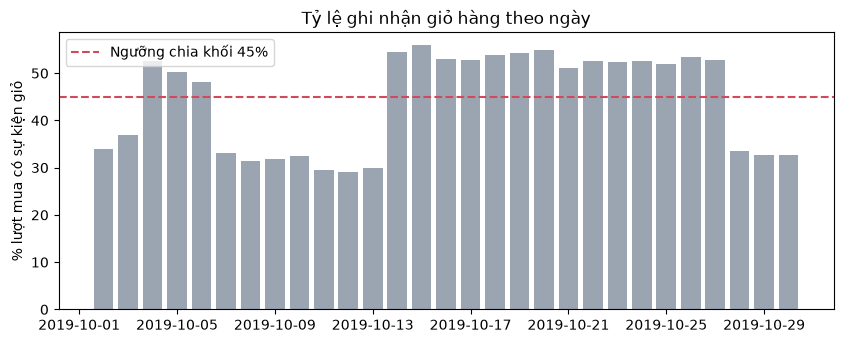

block,days,first_day,last_day,recorded_share
str,u32,date,date,f64
"""cao""",17,2019-10-04,2019-10-27,0.528241
"""thấp""",12,2019-10-02,2019-10-30,0.320427


In [5]:
recording_by_day = purchase_pairs.group_by("day").agg(recorded_share=pl.col("has_cart").mean(), purchases=pl.len()).sort("day")
day_block = recording_by_day.select("day", block=pl.when(pl.col("recorded_share") >= 0.45).then(pl.lit("cao")).otherwise(pl.lit("thấp")))
fig, ax = plt.subplots()
ax.bar(recording_by_day["day"], recording_by_day["recorded_share"] * 100, color="#9aa5b1")
ax.axhline(45, color="#d1495b", linestyle="--", label="Ngưỡng chia khối 45%")
ax.set(ylabel="% lượt mua có sự kiện giỏ", title="Tỷ lệ ghi nhận giỏ hàng theo ngày")
ax.legend()
plt.show()
(
    recording_by_day.join(day_block, on="day")
    .group_by("block")
    .agg(days=pl.len(), first_day=pl.col("day").min(), last_day=pl.col("day").max(),
         recorded_share=(pl.col("recorded_share") * pl.col("purchases")).sum() / pl.col("purchases").sum())
    .sort("block")
)

**Nhận xét:**
- Sau khi loại 550.170 phiên chạm biên, cohort còn **8.694.251 phiên** và 39,9 triệu sự kiện trong 29 ngày (2/10–30/10). Trong đó có 595.973 phiên có mua.
- Nhóm `apparel` có 293.861 phiên, trong đó 6.949 phiên có mua: đủ để so sánh các quy luật về phiên, nhịp thời gian và hành trình.
- **Giỏ hàng bị ghi nhận thiếu:** chỉ 61% lượt mua đồ điện tử có sự kiện giỏ đi kèm, đồ gia dụng 40%, và `apparel` gần như bằng 0. Theo ngày, tỷ lệ này nhảy giữa hai mức: khoảng **53%** (17 ngày, khối "cao") và khoảng **32%** (12 ngày, khối "thấp"). Mức nhảy theo khối ngày như vậy cho thấy hệ thống thu thập bị thay đổi, không phải hành vi khách.

Hệ quả: tỷ lệ thêm giỏ không đo trực tiếp được (mục 3 hiệu chỉnh lại), và nhóm `apparel` không dùng được cho phễu giỏ hàng.

In [6]:
assert events.filter(pl.col("day").is_in([dt.date(2019, 10, 1), dt.date(2019, 10, 31), dt.date(2019, 11, 1)])).height == 0
assert sessions["session"].n_unique() == sessions.height
assert sessions.filter(pl.col("buying")).height > 500_000
assert 250_000 < sessions.filter(pl.col("apparel")).height < 450_000
assert set(day_block["block"].unique()) == {"cao", "thấp"}

## 1. L1 — Mỗi phiên mua đi kèm bao nhiêu phiên không mua?

Generator dựng lưu lượng quanh số đơn OLTP, nên cần biết tỷ lệ r = phiên không mua ÷ phiên có mua. Nếu r ổn định giữa các ngày thì chỉ cần một con số.

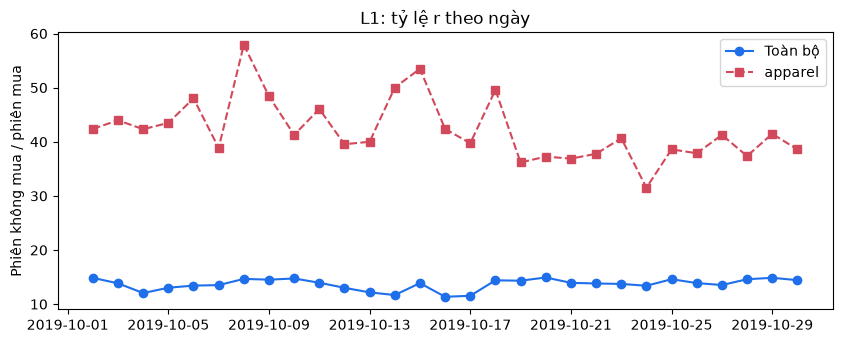

nhóm,r cả kỳ,r trung vị theo ngày,r p10 theo ngày,r p90 theo ngày
str,f64,f64,f64,f64
"""Toàn bộ""",13.59,13.88,12.05,14.74
"""apparel""",41.29,41.27,37.27,49.58


In [7]:
daily_ratio = (
    sessions.with_columns(day=pl.col("start").dt.date())
    .group_by("day", "apparel")
    .agg(buying=pl.col("buying").sum(), non_buying=(~pl.col("buying")).sum())
    .with_columns(ratio=pl.col("non_buying") / pl.col("buying"))
    .sort("day")
)
non_buying_per_buying = (~sessions["buying"]).sum() / sessions["buying"].sum()
apparel_sessions = sessions.filter(pl.col("apparel"))
non_buying_per_buying_apparel = (~apparel_sessions["buying"]).sum() / apparel_sessions["buying"].sum()
all_daily = (
    sessions.with_columns(day=pl.col("start").dt.date())
    .group_by("day").agg(ratio=(~pl.col("buying")).sum() / pl.col("buying").sum()).sort("day")
)
apparel_daily = daily_ratio.filter(pl.col("apparel"))
fig, ax = plt.subplots()
ax.plot(all_daily["day"], all_daily["ratio"], "o-", color="#1f6feb", label="Toàn bộ")
ax.plot(apparel_daily["day"], apparel_daily["ratio"], "s--", color="#d1495b", label="apparel")
ax.set(ylabel="Phiên không mua / phiên mua", title="L1: tỷ lệ r theo ngày")
ax.legend()
plt.show()
pl.DataFrame({
    "nhóm": ["Toàn bộ", "apparel"],
    "r cả kỳ": [round(non_buying_per_buying, 2), round(non_buying_per_buying_apparel, 2)],
    "r trung vị theo ngày": [round(all_daily["ratio"].median(), 2), round(apparel_daily["ratio"].median(), 2)],
    "r p10 theo ngày": [round(all_daily["ratio"].quantile(0.1), 2), round(apparel_daily["ratio"].quantile(0.1), 2)],
    "r p90 theo ngày": [round(all_daily["ratio"].quantile(0.9), 2), round(apparel_daily["ratio"].quantile(0.9), 2)],
})

**Nhận xét:** với toàn bộ dữ liệu, mỗi phiên có mua đi kèm khoảng **13,6 phiên không mua**, và tỷ lệ này ổn định giữa các ngày (80% số ngày nằm trong khoảng 12,0–14,7). Nhóm `apparel` cũng ổn định theo ngày nhưng ở mức cao hơn gấp ba: **41,3** (37,3–49,6). Khách xem quần áo ở cửa hàng này mua ít hơn hẳn, có lẽ vì quần áo là ngành phụ của một cửa hàng chủ yếu bán đồ điện tử.

**Quy luật L1:** số phiên không mua = r × số phiên có mua, r không đổi theo ngày. Dạng quy luật lặp lại ở cả hai nhóm; giá trị lấy theo `apparel` (r = 41,3) theo nguyên tắc của spec. Đây là chuyển nguồn, và r có thể cao hơn thực tế của một shop chỉ bán thời trang.

## 2. L2 — Một phiên có bao nhiêu lượt xem sản phẩm?

Đo số lượt `view` mỗi phiên, tách phiên có mua và không mua. Thử hai phân phối một tham số, chọn cái lệch ít hơn:
- **Hình học:** sau mỗi lượt xem, khách xem tiếp với xác suất 1 − p (p = 1/trung bình).
- **Log-series:** cùng dạng đuôi dài đã dùng cho số đơn mỗi khách ở notebook OLTP.

Phiên không có lượt xem nào (chỉ có sự kiện giỏ hoặc mua) được báo riêng và không đưa vào fit.

In [8]:
BUCKETS = ["1", "2", "3–4", "5–9", "10+"]


def bucket_share(values, edges=(1, 2, 3, 5, 10)):
    values = np.asarray(values)
    bounds = list(edges) + [np.inf]
    return np.array([((values >= lo) & (values < hi)).mean() for lo, hi in zip(bounds[:-1], bounds[1:])])


def model_buckets(model, param, edges=(1, 2, 3, 5, 10)):
    k = np.arange(1, edges[-1])
    if model == "geometric":
        pmf = param * (1 - param) ** (k - 1)
    else:
        pmf = -(param**k) / (k * np.log1p(-param))
    bounds = list(edges)
    shares = [pmf[(k >= lo) & (k < hi)].sum() for lo, hi in zip(bounds[:-1], bounds[1:])]
    return np.array(shares + [1 - pmf.sum()])


def log_series_theta(mean):
    return optimize.brentq(lambda t: -t / ((1 - t) * np.log1p(-t)) - mean, 1e-9, 1 - 1e-12)


def fit_views(values):
    shares = bucket_share(values)
    fits = {"geometric": 1 / values.mean(), "zero_truncated_log_series": log_series_theta(values.mean())}
    errors = {m: np.abs(model_buckets(m, p) - shares).max() * 100 for m, p in fits.items()}
    return shares, fits, errors


# Dạng mô hình chọn trên nhóm toàn bộ (nhiều dữ liệu); tham số đưa vào YAML lấy từ apparel (spec §3).
rows, shares_rows, views_models = [], [], {}
for kind, condition in (("buying", pl.col("buying")), ("non_buying", ~pl.col("buying"))):
    chosen = None
    for group, frame in (("Toàn bộ", sessions), ("apparel", apparel_sessions)):
        subset = frame.filter(condition)
        values = subset.filter(pl.col("views") > 0)["views"].to_numpy()
        shares, fits, errors = fit_views(values)
        chosen = chosen or min(errors, key=errors.get)
        if group == "apparel":
            views_models[kind] = {"model": chosen, ("p" if chosen == "geometric" else "theta"): round(float(fits[chosen]), 4)}
        rows.append({"kind": kind, "group": group, "sessions": subset.height,
                     "zero_view_%": percent((subset["views"] == 0).mean()), "mean_views": round(values.mean(), 2),
                     "model": chosen, "param": round(float(fits[chosen]), 4), "max_error_pp": round(errors[chosen], 1),
                     "other_model_error_pp": round(min(v for m, v in errors.items() if m != chosen), 1)})
        for source, values_pct in (("thực tế", percent(shares)), ("mô hình", percent(model_buckets(chosen, fits[chosen])))):
            shares_rows.append({"kind": kind, "group": group, "nguồn": source, **dict(zip(BUCKETS, values_pct.tolist()))})
l2_check = pl.DataFrame(rows)
display(l2_check)
pl.DataFrame(shares_rows)

kind,group,sessions,zero_view_%,mean_views,model,param,max_error_pp,other_model_error_pp
str,str,i64,f64,f64,str,f64,f64,f64
"""buying""","""Toàn bộ""",595973,0.1,5.58,"""geometric""",0.1793,8.3,16.3
"""buying""","""apparel""",6949,0.1,9.59,"""geometric""",0.1043,6.4,19.4
"""non_buying""","""Toàn bộ""",8098278,0.0,4.33,"""zero_truncated_log_series""",0.9138,1.2,15.4
"""non_buying""","""apparel""",286912,0.0,4.72,"""zero_truncated_log_series""",0.9241,1.3,13.4


kind,group,nguồn,1,2,3–4,5–9,10+
str,str,str,f64,f64,f64,f64,f64
"""buying""","""Toàn bộ""","""thực tế""",17.1,23.0,24.5,21.2,14.2
"""buying""","""Toàn bộ""","""mô hình""",17.9,14.7,22.0,28.5,16.9
"""buying""","""apparel""","""thực tế""",7.9,13.7,21.5,26.2,30.7
"""buying""","""apparel""","""mô hình""",10.4,9.3,15.9,27.3,37.1
"""non_buying""","""Toàn bộ""","""thực tế""",38.5,17.4,17.6,15.8,10.7
"""non_buying""","""Toàn bộ""","""mô hình""",37.3,17.0,17.5,16.8,11.4
"""non_buying""","""apparel""","""thực tế""",34.5,16.8,18.5,17.8,12.4
"""non_buying""","""apparel""","""mô hình""",35.8,16.6,17.3,17.1,13.2


**Nhận xét:**
- **Phiên không mua:** log-series khớp tốt ở cả hai nhóm (lệch khoảng 1,2–1,3 điểm %), tham số gần như trùng nhau (θ ≈ 0,91 và 0,92). Khoảng 35–39% phiên chỉ xem đúng một sản phẩm rồi rời đi.
- **Phiên có mua:** khách xem nhiều hơn (trung bình 5,6 lượt; với `apparel` là 9,6). Số lượt xem có **đỉnh ở 2 lượt** (xem sản phẩm, quay lại xem lần nữa rồi mua), nên phân phối hình học, vốn luôn giảm dần, lệch tối đa 6–8 điểm %: thiếu ở mức 2 lượt (14,7% so với thực tế 23,0%) và thừa ở nhóm nhiều lượt (5–9 lượt với toàn bộ, 10+ với `apparel`). Mức lệch này được chấp nhận vì log-series còn lệch nhiều hơn (16–19 điểm %).
- Gần như mọi phiên đều có ít nhất một lượt xem (phiên 0 lượt xem chiếm ≤ 0,1%).

**Quy luật L2:** số lượt xem của phiên không mua theo **log-series (θ = 0,924)**, của phiên có mua theo **phân phối hình học (p = 0,104)**; tham số lấy từ `apparel`.

In [9]:
assert 5 < non_buying_per_buying < 30
for kind in ("buying", "non_buying"):
    assert views_models[kind]["model"] in {"geometric", "zero_truncated_log_series"}
assert l2_check["max_error_pp"].max() < 10

## 3. L3 — Phễu giỏ hàng, có hiệu chỉnh ghi nhận thiếu

Mục 0.1 cho thấy chỉ một phần sự kiện giỏ hàng được ghi lại. Cách hiệu chỉnh gồm ba bước, đo trên toàn bộ dữ liệu (nhóm `apparel` gần như không có sự kiện giỏ):

1. **Tỷ lệ ghi nhận `q`:** % lượt mua có sự kiện giỏ đi kèm. Vì lượt mua nào cũng đã qua giỏ, phần thiếu là do hệ thống không ghi lại.
2. **Đã thêm giỏ thì mua:** trong các lượt thêm giỏ *được ghi lại*, bao nhiêu % sản phẩm đó được mua trong cùng phiên. Nếu việc ghi thiếu là ngẫu nhiên (không phụ thuộc khách có mua hay không), tỷ lệ này không bị ảnh hưởng.
3. **Phiên không mua có thêm giỏ:** % phiên không mua có sự kiện giỏ được ghi lại, chia cho `q` để bù phần bị thiếu.

**Cách kiểm tra:** tính riêng trên khối ngày ghi nhận cao (khoảng 53%) và khối thấp (khoảng 32%). Nếu cách hiệu chỉnh đúng, hai khối phải cho cùng kết quả dù tỷ lệ ghi nhận khác nhau. Ngưỡng đặt trước: lệch quá 5 điểm % thì L3 chuyển thành giả định.

In [10]:
session_block = sessions.with_columns(day=pl.col("start").dt.date()).join(day_block, on="day").select("session", "block", "buying", "carts")
pairs = (
    events.filter(pl.col("event_type").is_in(["cart", "purchase"]))
    .group_by("session", "product_id")
    .agg(has_cart=(pl.col("event_type") == "cart").any(), has_purchase=(pl.col("event_type") == "purchase").any())
    .join(session_block.select("session", "block"), on="session")
)


def funnel_row(pair_frame, session_frame, label):
    recorded = pair_frame.filter(pl.col("has_purchase"))["has_cart"].mean()
    purchase_given_cart = pair_frame.filter(pl.col("has_cart"))["has_purchase"].mean()
    observed_cart_rate = (session_frame.filter(~pl.col("buying"))["carts"] > 0).mean()
    return {"block": label, "recorded_share": recorded, "purchase_given_cart": purchase_given_cart,
            "observed_non_buying_cart_rate": observed_cart_rate,
            "non_buying_cart_rate": min(1.0, observed_cart_rate / recorded)}


rows = [funnel_row(pairs.filter(pl.col("block") == b), session_block.filter(pl.col("block") == b), b) for b in ("cao", "thấp")]
rows.append(funnel_row(pairs, session_block, "gộp"))
funnel_table = pl.DataFrame(rows)
funnel_by_block = funnel_table.select("block", "recorded_share", "purchase_given_cart", "non_buying_cart_rate")
block_gap_pp = (
    funnel_by_block.filter(pl.col("block") != "gộp").select(pl.exclude("block", "recorded_share")).to_numpy()
)
block_gap_pp = np.abs(block_gap_pp[0] - block_gap_pp[1]) * 100
funnel_source = "assumption" if (block_gap_pp > 5).any() else "transfer"
funnel_reason = (
    None if funnel_source == "transfer"
    else f"hai khối ngày lệch {block_gap_pp.max():.1f} điểm % (> 5): hiệu chỉnh không ổn định"
)
print("Chênh lệch giữa hai khối (điểm %): purchase_given_cart", round(block_gap_pp[0], 1),
      "| non_buying_cart_rate", round(block_gap_pp[1], 1), "→ source:", funnel_source)
funnel_table.with_columns(pl.exclude("block").round(4))

Chênh lệch giữa hai khối (điểm %): purchase_given_cart 7.1 | non_buying_cart_rate 2.2 → source: assumption


block,recorded_share,purchase_given_cart,observed_non_buying_cart_rate,non_buying_cart_rate
str,f64,f64,f64,f64
"""cao""",0.5282,0.4658,0.0431,0.0816
"""thấp""",0.3205,0.5364,0.0192,0.06
"""gộp""",0.448,0.4834,0.0336,0.075


**Nhận xét:**
- **Phiên không mua có thêm giỏ:** số quan sát được chênh nhau hơn hai lần giữa hai khối (4,3% so với 1,9%), đúng như dự đoán khi tỷ lệ ghi nhận khác nhau. Sau hiệu chỉnh, hai khối còn 8,2% và 6,0%, lệch 2,2 điểm %: hiệu chỉnh đã kéo hai khối lại gần nhau.
- **Đã thêm giỏ thì mua:** khối ghi nhận cao cho 46,6%, khối thấp cho 53,6%, **lệch 7,1 điểm %**, vượt ngưỡng 5 điểm % đặt trước. Ở những ngày ghi nhận thấp, các lượt thêm giỏ dẫn tới mua có vẻ được ghi lại nhiều hơn, tức việc ghi thiếu **không hoàn toàn ngẫu nhiên**, nên giả định của bước 2 không đứng vững.

**Kết luận L3:** theo ngưỡng đã đặt trước, phễu giỏ hàng là **giả định** (`source: assumption`), không phải quy luật đo được. Giá trị dùng tạm là số gộp cả tháng: khoảng **48%** lượt thêm giỏ dẫn tới mua, và khoảng **7,5%** phiên không mua có thêm giỏ. Đây là điểm khởi đầu hợp lý về độ lớn, không phải số đo chính xác.

In [11]:
assert funnel_by_block.height == 3
assert funnel_by_block.select(pl.all().exclude("block").is_between(0, 1).all()).row(0) == (True, True, True)
gap = funnel_by_block.filter(pl.col("block") != "gộp").select(pl.exclude("block", "recorded_share")).to_numpy()
expected = "assumption" if (np.abs(gap[0] - gap[1]) * 100 > 5).any() else "transfer"
assert funnel_source == expected

## 4. L4 — Hai sự kiện liên tiếp trong phiên cách nhau bao lâu?

Đo số giây giữa hai sự kiện liên tiếp của cùng một phiên. Khoảng cách bằng 0 (hai sự kiện trong cùng một giây, thường do trang gửi nhiều sự kiện cùng lúc) được báo riêng; phân phối log-normal được fit trên các khoảng cách lớn hơn 0.

In [12]:
apparel_ids = sessions.filter(pl.col("apparel")).select("session")
gaps = events.select(
    "session", gap=(pl.col("ts").diff().over("session").dt.total_seconds())
).filter(pl.col("gap").is_not_null())
GAP_BUCKETS = ["< 10 giây", "10–60 giây", "1–5 phút", "> 5 phút"]
GAP_EDGES = [0, 10, 60, 300, np.inf]
rows, shares_rows, gap_fits = [], [], {}
for group, frame in (("Toàn bộ", gaps), ("apparel", gaps.join(apparel_ids, on="session"))):
    values = frame["gap"].to_numpy()
    positive = values[values > 0]
    log_values = np.log(positive)
    median, sigma = float(np.exp(log_values.mean())), float(log_values.std())
    gap_fits[group] = {"median_seconds": round(median, 1), "sigma": round(sigma, 3), "zero_share": round(float((values == 0).mean()), 4)}
    observed = np.array([((positive > lo) & (positive <= hi)).mean() for lo, hi in zip(GAP_EDGES[:-1], GAP_EDGES[1:])])
    cdf = stats.lognorm.cdf(GAP_EDGES[1:-1], sigma, scale=median)
    model = np.diff(np.concatenate([[0], cdf, [1]]))
    rows.append({"group": group, "gaps": len(values), "zero_%": percent((values == 0).mean()),
                 "median_seconds": round(median, 1), "sigma": round(sigma, 3),
                 "max_error_pp": round(float(np.abs(observed - model).max() * 100), 1)})
    for source, shares in (("thực tế", observed), ("mô hình", model)):
        shares_rows.append({"group": group, "nguồn": source, **dict(zip(GAP_BUCKETS, percent(shares).tolist()))})
event_gap = gap_fits["apparel"]
l4_check = pl.DataFrame(rows)
display(l4_check)
pl.DataFrame(shares_rows)

group,gaps,zero_%,median_seconds,sigma,max_error_pp
str,i64,f64,f64,f64,f64
"""Toàn bộ""",31251581,0.1,37.0,1.115,6.5
"""apparel""",1135949,0.0,36.1,0.938,4.4


group,nguồn,< 10 giây,10–60 giây,1–5 phút,> 5 phút
str,str,f64,f64,f64,f64
"""Toàn bộ""","""thực tế""",10.1,61.2,25.3,3.4
"""Toàn bộ""","""mô hình""",12.0,54.7,30.2,3.0
"""apparel""","""thực tế""",7.5,66.4,24.3,1.9
"""apparel""","""mô hình""",8.6,62.0,28.2,1.2


**Nhận xét:** khoảng cách giữa hai sự kiện có trung vị khoảng **36–37 giây** ở cả hai nhóm; phần lớn (61–66%) rơi vào 10–60 giây và chỉ 2–3% dài hơn 5 phút. Sự kiện trùng giây gần như không có (≤ 0,1%). Log-normal lệch tối đa 4,4 điểm % với `apparel` và 6,5 điểm % với toàn bộ dữ liệu; mô hình hơi thiếu ở khoảng 10–60 giây và thừa ở 1–5 phút.

**Quy luật L4:** khoảng cách giữa hai request liên tiếp trong phiên theo **log-normal, trung vị 36,1 giây, σ = 0,94** (theo `apparel`).

## 5. L5 — Sản phẩm nào được xem?

(a) Với mỗi sản phẩm có ít nhất một lượt mua, lượt xem tăng theo lượt mua thế nào? Nếu log(lượt xem) tăng tuyến tính theo log(lượt mua) với độ dốc b, thì lượt xem ∝ lượt mua^b; generator có thể suy lượt xem từ độ phổ biến của sản phẩm trong OLTP.

(b) Trong phiên có mua, bao nhiêu % lượt xem là chính các sản phẩm được mua?

In [13]:
product_counts = (
    events.group_by("product_id")
    .agg(views=(pl.col("event_type") == "view").sum(), purchases=(pl.col("event_type") == "purchase").sum(),
         apparel=pl.col("is_apparel").any())
    .filter((pl.col("purchases") > 0) & (pl.col("views") > 0))
)


def top_share(values, fraction=0.1):
    ordered = np.sort(values)[::-1]
    return ordered[: max(1, int(len(ordered) * fraction))].sum() / ordered.sum()


rows, exponents = [], {}
for group, frame in (("Toàn bộ", product_counts), ("apparel", product_counts.filter(pl.col("apparel")))):
    views, purchases = frame["views"].to_numpy().astype(float), frame["purchases"].to_numpy().astype(float)
    slope, intercept = np.polyfit(np.log(purchases), np.log(views), 1)
    exponents[group] = float(slope)
    rows.append({"group": group, "products": frame.height, "b": round(slope, 3),
                 "corr_log": round(float(np.corrcoef(np.log(purchases), np.log(views))[0, 1]), 3),
                 "top10_view_share_%: thực tế": percent(top_share(views)),
                 "top10_view_share_%: mô hình": percent(top_share(purchases**slope))})
views_exponent = round(exponents["apparel"], 4)
l5a_check = pl.DataFrame(rows)
l5a_check

group,products,b,corr_log,top10_view_share_%: thực tế,top10_view_share_%: mô hình
str,i64,f64,f64,f64,f64
"""Toàn bộ""",41044,0.926,0.789,70.0,77.4
"""apparel""",2427,1.037,0.716,51.2,44.8


In [14]:
purchased = events.filter(pl.col("event_type") == "purchase").select("session", "product_id").unique().with_columns(bought=pl.lit(True))
buying_views = (
    events.filter(pl.col("event_type") == "view")
    .join(sessions.filter(pl.col("buying")).select("session", "apparel"), on="session")
    .join(purchased, on=["session", "product_id"], how="left")
    .with_columns(pl.col("bought").fill_null(False))
)
l5b = pl.DataFrame({
    "group": ["Toàn bộ", "apparel"],
    "purchased_view_share_%": [percent(buying_views["bought"].mean()),
                               percent(buying_views.filter(pl.col("apparel"))["bought"].mean())],
})
purchased_view_share = round(float(buying_views.filter(pl.col("apparel"))["bought"].mean()), 4)
l5b

group,purchased_view_share_%
str,f64
"""Toàn bộ""",51.4
"""apparel""",31.7


**Nhận xét:**
- **(a)** Độ dốc b gần bằng 1 ở cả hai nhóm (0,93 với toàn bộ, 1,04 với `apparel`; tương quan log 0,72–0,79): **lượt xem gần như tỷ lệ thuận với lượt mua**, tức mỗi sản phẩm có tỷ lệ chuyển đổi xem → mua tương đối giống nhau. Dùng lượt mua^b để dự đoán thì tỷ trọng lượt xem của top 10% sản phẩm lệch khoảng 6–7 điểm % (`apparel`: thực tế 51,2%, mô hình 44,8%): phần còn lại là khác biệt riêng của từng sản phẩm mà một tham số không mô tả được.
- **(b)** Trong phiên có mua, **31,7%** lượt xem với `apparel` (51,4% với toàn bộ dữ liệu) là chính sản phẩm được mua; phần còn lại là xem các sản phẩm khác trước khi chọn.

**Quy luật L5:** trọng số lượt xem của một sản phẩm = (trọng số mua của nó trong OLTP)^b với **b = 1,04**; trong phiên có mua, **31,7%** lượt xem là sản phẩm được mua, còn lại chọn theo trọng số lượt xem.

In [15]:
assert event_gap["median_seconds"] > 0 and event_gap["sigma"] > 0
assert 0 <= event_gap["zero_share"] < 1
assert 0 < views_exponent < 2
assert 0 < purchased_view_share < 1
assert l4_check["max_error_pp"].max() < 10

## 6. L6 — Khách có xem trước rồi mới quay lại mua không?

Với mỗi lượt mua (cặp phiên × sản phẩm), đếm số phiên **trước đó** của cùng khách có xem chính sản phẩm đó, và số ngày từ lần xem đầu tiên tới lúc mua.

**Giới hạn đo:** dữ liệu chỉ có một tháng, nên hành trình bắt đầu trước cohort sẽ bị cắt. Vì vậy chỉ xét lượt mua từ ngày 15/10 và nhìn lại tối đa 14 ngày. Khách mua lần đầu thấy sản phẩm ngay trong phiên mua được tính là 0 phiên trước, không bị loại khỏi mẫu số.

In [16]:
LOOKBACK = dt.timedelta(days=14)
buy = (
    events.filter(pl.col("event_type") == "purchase")
    .group_by("session", "product_id")
    .agg(user_id=pl.col("user_id").first(), purchase_ts=pl.col("ts").min(), apparel=pl.col("is_apparel").any())
    .join(sessions.select("session", "start"), on="session")
    .with_columns(purchase_day=pl.col("purchase_ts").dt.date())
    .filter(pl.col("purchase_day") >= dt.date(2019, 10, 15))
)
prior_views = (
    events.filter(pl.col("event_type") == "view")
    .join(buy.select("user_id", "product_id").unique(), on=["user_id", "product_id"], how="semi")
    .group_by("session", "user_id", "product_id")
    .agg(first_view=pl.col("ts").min())
    .join(sessions.select("session", view_start="start"), on="session")
)
matched = (
    buy.join(prior_views, on=["user_id", "product_id"], how="inner", suffix="_prior")
    .filter((pl.col("session_prior") != pl.col("session"))
            & (pl.col("view_start") < pl.col("start"))
            & (pl.col("view_start") >= pl.col("start") - LOOKBACK))
    .group_by("session", "product_id")
    .agg(prior_sessions=pl.len(), first_prior_view=pl.col("first_view").min())
)
l6_purchases = (
    buy.join(matched, on=["session", "product_id"], how="left")
    .with_columns(prior_sessions=pl.col("prior_sessions").fill_null(0))
    .with_columns(days_from_first_view=pl.when(pl.col("prior_sessions") > 0)
                  .then((pl.col("purchase_ts") - pl.col("first_prior_view")).dt.total_seconds() / 86400))
)
JOURNEY_BUCKETS = ["0", "1", "2", "3+"]
rows, shares_rows, fits = [], [], {}
for group, frame in (("Toàn bộ", l6_purchases), ("apparel", l6_purchases.filter(pl.col("apparel")))):
    k = frame["prior_sessions"].to_numpy()
    observed = np.array([(k == 0).mean(), (k == 1).mean(), (k == 2).mean(), (k >= 3).mean()])
    p = 1 / (1 + k.mean())
    theta = log_series_theta((k + 1).mean())
    candidates = {
        "geometric": (p, np.array([p, p * (1 - p), p * (1 - p) ** 2, (1 - p) ** 3])),
        "shifted_log_series": (theta, np.append(log_series_pmf := -(theta ** np.arange(1, 4)) / (np.arange(1, 4) * np.log1p(-theta)),
                                                 1 - log_series_pmf.sum())),
    }
    errors = {name: np.abs(observed - shares).max() * 100 for name, (_, shares) in candidates.items()}
    if group == "Toàn bộ":
        journey_model = min(errors, key=errors.get)
    param, model = candidates[journey_model]
    days = frame.filter(pl.col("prior_sessions") > 0)["days_from_first_view"].to_numpy()
    fits[group] = (param, days.mean())
    rows.append({"group": group, "purchases": frame.height, "model": journey_model, "param": round(float(param), 4),
                 "max_error_pp": round(float(errors[journey_model]), 1),
                 "other_model_error_pp": round(float(min(v for n, v in errors.items() if n != journey_model)), 1),
                 "days_mean": round(days.mean(), 2), "days_median: thực tế": round(float(np.median(days)), 2),
                 "days_median: mô hình mũ": round(days.mean() * np.log(2), 2)})
    for source, shares in (("thực tế", observed), ("mô hình", model)):
        shares_rows.append({"group": group, "nguồn": source, **dict(zip(JOURNEY_BUCKETS, percent(shares).tolist()))})
prior_sessions_model = {"model": journey_model, ("p" if journey_model == "geometric" else "theta"): round(float(fits["apparel"][0]), 4)}
days_to_purchase_mean = round(float(fits["apparel"][1]), 2)
l6_check = pl.DataFrame(rows)
display(l6_check)
pl.DataFrame(shares_rows)

group,purchases,model,param,max_error_pp,other_model_error_pp,days_mean,days_median: thực tế,days_median: mô hình mũ
str,i64,str,f64,f64,f64,f64,f64,f64
"""Toàn bộ""",365330,"""shifted_log_series""",0.788,4.8,13.9,4.28,2.4,2.96
"""apparel""",5014,"""shifted_log_series""",0.718,3.6,10.6,3.13,1.47,2.17


group,nguồn,0,1,2,3+
str,str,f64,f64,f64,f64
"""Toàn bộ""","""thực tế""",55.6,18.9,9.3,16.2
"""Toàn bộ""","""mô hình""",50.8,20.0,10.5,18.7
"""apparel""","""thực tế""",60.3,17.9,8.5,13.4
"""apparel""","""mô hình""",56.7,20.4,9.7,13.2


**Nhận xét:**
- **Phần lớn lượt mua không xem trước:** 60% lượt mua quần áo (56% với toàn bộ dữ liệu) không có phiên nào trước đó xem chính sản phẩm đó trong 14 ngày. Nhưng có một đuôi dài: 13–16% lượt mua đã xem sản phẩm từ 3 phiên trước trở lên.
- Phân phối hình học không mô tả được đồng thời phần lớn ở 0 và đuôi dài (lệch 10,6–13,9 điểm %). **Log-series dịch 1** (số phiên trước + 1 theo log-series, giống dạng đã dùng ở L2) lệch tối đa 3,6 điểm % với `apparel` và 4,8 điểm % với toàn bộ.
- **Thời gian quay lại:** trong các lượt mua có xem trước, lần xem đầu cách lúc mua trung bình 3,1 ngày (`apparel`), trung vị 1,5 ngày. Phân phối mũ với cùng trung bình cho trung vị 2,2 ngày, tức **đánh giá thấp số khách quay lại mua rất nhanh**; mức lệch này được ghi nhận nhưng vẫn giữ phân phối mũ như spec để chỉ dùng một tham số.

**Quy luật L6:** số phiên xem trước của một lượt mua = X − 1, với X theo **log-series (θ = 0,718)**; khoảng cách từ lần xem đầu tới lúc mua theo **phân phối mũ, trung bình 3,13 ngày**, giới hạn trong 14 ngày.

In [17]:
assert l6_purchases["purchase_day"].min() >= dt.date(2019, 10, 15)
assert (l6_purchases["prior_sessions"] == 0).sum() > 0
assert 0 < (prior_sessions_model.get("p") or prior_sessions_model["theta"]) <= 1
assert 0 < days_to_purchase_mean <= 14

## 7. Giả định: những gì dữ liệu không có

eCommerce Behavior chỉ ghi `view`, `cart`, `purchase`. Các request khác mà log FastAPI có, cùng một số tham số kịch bản, được đặt bằng giả định (`source: assumption` trong YAML):

| Giả định | Giá trị | Lý do |
|---|---|---|
| Phiên mở đầu bằng `category_list` hoặc `catalog_search` trước lượt xem đầu tiên | luôn có | Khách cần một trang danh sách để chọn sản phẩm; dữ liệu không ghi trang danh sách |
| `cart_read` rồi `checkout_quote` trước `checkout_submit` | luôn có | Đúng thứ tự nghiệp vụ của API checkout |
| Tỷ lệ phiên không mua ở trạng thái ẩn danh | 60% | Dữ liệu chỉ có `user_id`, không phân biệt đăng nhập; phiên có mua luôn đăng nhập |
| Lưu lượng ngày sale tăng cùng hệ số với số đơn OLTP | có | eCommerce Behavior không có hiệu ứng Black Friday để đo |
| Giờ bắt đầu phiên theo phân bố giờ đặt hàng của OLTP | có | Không đo lại; giữ một nguồn duy nhất cho giờ |
| Phễu giỏ hàng (mục 3) | 48% / 7,5% | Hiệu chỉnh không vượt qua kiểm tra hai khối ngày |

## 8. Tổng hợp

| Mã | Hành vi | Quy luật | Tham số (`apparel`) | Kiểm tra | Giống nhau giữa hai nhóm? |
|---|---|---|---|---|---|
| L1 | Lưu lượng | Phiên không mua = r × phiên có mua | r = 41,3 | r ổn định theo ngày | Dạng giống; giá trị khác (13,6 với toàn bộ) |
| L2 | Độ dài phiên | Không mua: log-series; có mua: hình học | θ = 0,924; p = 0,104 | Lệch 1,3 và 6,4 điểm % | Không mua: giống; có mua: khác |
| L3 | Phễu giỏ hàng | **Giả định** | 48% / 7,5% | Hai khối ngày lệch 7,1 điểm % (> 5) | Không đo được trên `apparel` |
| L4 | Nhịp thời gian | Log-normal | trung vị 36,1 giây, σ = 0,94 | Lệch 4,4 điểm % | Giống (trung vị 36–37 giây) |
| L5 | Sản phẩm được xem | Lượt xem ∝ lượt mua^b; 31,7% lượt xem trong phiên mua là sản phẩm được mua | b = 1,04 | Top 10% lệch 6,4 điểm % | b giống (0,93–1,04); tỷ lệ (b) khác |
| L6 | Hành trình nhiều phiên | Số phiên trước + 1 theo log-series; thời gian quay lại theo phân phối mũ | θ = 0,718; trung bình 3,13 ngày | Lệch 3,6 điểm %; trung vị lệch 0,7 ngày | Giống về dạng |

Mọi tham số đo được mang nhãn **transfer**: chúng đến từ một cửa hàng đa ngành ở Nga, nhóm `apparel` chỉ là ngành phụ của cửa hàng đó. Ô dưới in tham số theo đúng khóa của `generator/configs/access_logs.yml`; ô cuối khẳng định file YAML khớp với các số này.

In [18]:
parameters = {
    "sessions": {
        "non_buying_per_buying": {"value": round(float(non_buying_per_buying_apparel), 2)},
        "views_per_session": {"buying": views_models["buying"], "non_buying": views_models["non_buying"]},
    },
    "funnel": {
        "purchase_given_cart": round(float(funnel_by_block.filter(pl.col("block") == "gộp")["purchase_given_cart"].item()), 4),
        "non_buying_cart_rate": round(float(funnel_by_block.filter(pl.col("block") == "gộp")["non_buying_cart_rate"].item()), 4),
    },
    "timing": {"event_gap_seconds": {"median": event_gap["median_seconds"], "sigma": event_gap["sigma"]}},
    "products": {"views_vs_purchases_exponent": views_exponent, "purchased_product_view_share": purchased_view_share},
    "journey": {
        "prior_sessions": prior_sessions_model,
        "days_first_view_to_purchase": {"mean": days_to_purchase_mean, "max_days": LOOKBACK.days},
    },
}
print("funnel source:", funnel_source, "|", funnel_reason)
print(json.dumps(parameters, ensure_ascii=False, indent=1))

funnel source: assumption | hai khối ngày lệch 7.1 điểm % (> 5): hiệu chỉnh không ổn định
{
 "sessions": {
  "non_buying_per_buying": {
   "value": 41.29
  },
  "views_per_session": {
   "buying": {
    "model": "geometric",
    "p": 0.1043
   },
   "non_buying": {
    "model": "zero_truncated_log_series",
    "theta": 0.9241
   }
  }
 },
 "funnel": {
  "purchase_given_cart": 0.4834,
  "non_buying_cart_rate": 0.075
 },
 "timing": {
  "event_gap_seconds": {
   "median": 36.1,
   "sigma": 0.938
  }
 },
 "products": {
  "views_vs_purchases_exponent": 1.0365,
  "purchased_product_view_share": 0.3174
 },
 "journey": {
  "prior_sessions": {
   "model": "shifted_log_series",
   "theta": 0.718
  },
  "days_first_view_to_purchase": {
   "mean": 3.13,
   "max_days": 14
  }
 }
}


In [19]:
config = yaml.safe_load((repo_root / "generator/configs/access_logs.yml").read_text())
assert config["schema_version"] == 1 and config["window_days"] == 30
assert config["funnel"]["source"] == funnel_source
assert config["assumptions"]["source"] == "assumption"


def numbers(tree, prefix=""):
    for key, value in tree.items():
        if isinstance(value, dict):
            yield from numbers(value, f"{prefix}{key}.")
        elif isinstance(value, (int, float)) and not isinstance(value, bool):
            yield f"{prefix}{key}", value


expected = dict(numbers(parameters))
actual = dict(numbers({k: config[k] for k in parameters}))
assert expected.keys() == actual.keys(), expected.keys() ^ actual.keys()
assert all(abs(expected[k] - actual[k]) <= 5e-4 * max(1, abs(expected[k])) for k in expected)